# Лабораторная работа №5: CLIP: zero-shot-классификация и мультимодальный поиск

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.


## Цели обучения

После работы студент должен уметь:

- Сравнить prompt templates в zero-shot classification.
- Построить text-to-image retrieval.
- Дообучить projection head и оценить Recall@K.


## Теоретическая часть

CLIP обучает image encoder и text encoder в общем нормированном пространстве. Zero-shot logits пропорциональны cosine similarity между изображением и текстовыми шаблонами классов.

![CLIP](https://raw.githubusercontent.com/openai/CLIP/main/CLIP.png)


### Математическая постановка

$$s(x,t)=\frac{f_I(x)^\top f_T(t)}{\|f_I(x)\|\|f_T(t)\|},\qquad p(c\mid x)=\operatorname{softmax}(s(x,t_c)/\tau).$$
Для retrieval используются Recall@K и median rank.


### Материалы

- [OpenCLIP](https://github.com/mlfoundations/open_clip)
- [CLIP paper](https://arxiv.org/abs/2103.00020)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практическое задание

1. Сравнить prompt templates в zero-shot classification.
2. Построить text-to-image retrieval.
3. Дообучить projection head и оценить Recall@K.

**Обязательные артефакты:** код, конфигурация, метрики, минимум одна контролируемая ablation, примеры ошибок и краткие выводы.


### Профиль вычислений

- **Основной режим:** OpenCLIP ViT-B-32 frozen/малый projection head.
- **Ограничение данных:** CIFAR-10 или до 5 000 пар.
- **Fallback:** CPU на 500 объектах.
- Все длительные этапы должны сохранять checkpoint и продолжаться после перезапуска. Оценка не зависит от размера модели: важны корректность эксперимента и выводы.


**Оценивание.** Десять обязательных предметных этапов по 1 баллу: основная часть — 10 баллов. Творческий бонус — отдельно 1 балл, не заменяет обязательные этапы. Полный режим оценивается по реальным данным и обучению; `FAST_DEV_RUN=True` служит только smoke-проверкой, его показатели не являются отчётными.


## Реализация


In [1]:
# Базовое воспроизводимое окружение
from pathlib import Path
import json, os, random, time
import numpy as np

SEED = 42
FAST_DEV_RUN = False  # True — только проверка связности на уменьшенной выборке; не отчётный результат
ARTIFACTS = Path(os.getenv("CV_ARTIFACTS", "artifacts"))
ARTIFACTS.mkdir(exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
try:
    import torch
    torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
except ImportError:
    torch = None
    DEVICE = "cpu"
# Датасеты курса лежат в общем каталоге <корень курса>/data:
# notebook выполняется из labs/lab_XX_*/, поэтому корень курса — cwd.parent.parent.
# Для локальных запусков вне labs/ также поднимаемся, пока не найдём каталог data с CIFAR.
_CANDIDATES = [Path.cwd().parent.parent / "data", Path.cwd().parent / "data", Path.cwd() / "data"]
DATA_ROOT = Path(os.getenv("CV_COURSE_DATA") or next((c for c in _CANDIDATES if (c / "cifar-10-batches-py").exists()), _CANDIDATES[0]))
DATA_ROOT.mkdir(parents=True, exist_ok=True)
print({"device": DEVICE, "fast_dev_run": FAST_DEV_RUN, "data_root": str(DATA_ROOT)})


{'device': 'cuda', 'fast_dev_run': False, 'data_root': 'c:\\Users\\eric1\\Desktop\\data'}


In [2]:
def check(condition, message):
    """Мини-проверка в стиле YAAM: молчит, если всё хорошо; печатает, если найдена проблема."""
    if condition:
        print(f"✔ {message}")
    else:
        print(f"✘ ВНИМАНИЕ: {message}")

### Данные и предобученный CLIP

*Вес: 1 балл.*

**Постановка.** Индекс поиска и обучающие пары должны состоять из разных изображений.

Выполните следующие действия:
1. Загрузите CIFAR-10 train/test и OpenCLIP ViT-B-32.
2. Определите список классов и независимый test-загрузчик.

**Результат.** Объекты model, train_pairs, ds, classes, loader.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [3]:
import torch
import torch.nn.functional as F
import torchvision
from torch.utils.data import DataLoader, Dataset, TensorDataset
import open_clip

def load_clip():
    for pretrained in ["openai", "laion2b_s34b_b79k"]:
        try:
            m, _, p = open_clip.create_model_and_transforms("ViT-B-32", pretrained=pretrained)
            print(f"CLIP загружен: ViT-B-32 / {pretrained}")
            return m, p, pretrained
        except Exception as e:
            print(f"{pretrained} не скачался: {e}")
    raise RuntimeError("CLIP не загрузился — проверь pip install open_clip_torch")

model, preprocess, PRETRAINED = load_clip()
model.eval().to(DEVICE)
tokenizer = open_clip.get_tokenizer("ViT-B-32")

base_train = torchvision.datasets.CIFAR10(root=DATA_ROOT, train=True, download=True)
base_test  = torchvision.datasets.CIFAR10(root=DATA_ROOT, train=False, download=True)
classes = base_train.classes
print("Классы:", classes)

class ClipCIFAR(Dataset):
    def __init__(self, base, indices, tf):
        self.base, self.idx, self.tf = base, list(map(int, indices)), tf
    def __len__(self): return len(self.idx)
    def __getitem__(self, i):
        img, y = self.base[self.idx[i]]
        return self.tf(img), y

rng = np.random.RandomState(SEED)
perm = rng.permutation(len(base_train))
if FAST_DEV_RUN:
    train_pairs, test_idx = perm[:200], np.arange(200)
else:
    train_pairs, test_idx = perm[:5000], np.arange(2000)  # лимит профиля: до 5000 пар

ds = ClipCIFAR(base_test, test_idx, preprocess)          # независимый test
loader = DataLoader(ds, batch_size=128, shuffle=False, num_workers=0)
ds_train_pairs = ClipCIFAR(base_train, train_pairs, preprocess)

with open(ARTIFACTS / "dataset_manifest.json", "w") as f:
    json.dump({"train_pairs": int(len(train_pairs)), "test": int(len(test_idx)),
               "pretrained": PRETRAINED, "seed": SEED}, f, indent=4)
print({"train_pairs": len(train_pairs), "test": len(test_idx)})
check(True, "model, train_pairs, ds, classes, loader готовы")


c:\Users\eric1\.conda\envs\fmi-cv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\eric1\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            

c:\Users\eric1\.conda\envs\fmi-cv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\eric1\.cache\huggingface\hub\models--timm--vit_base_patch32_clip_224.openai. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Users\eric1\.conda\envs\fmi-cv\Lib\site-packages\open_clip\factory.py:450: UserWarning: QuickG

CLIP загружен: ViT-B-32 / openai
Классы: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
{'train_pairs': 5000, 'test': 2000}
✔ model, train_pairs, ds, classes, loader готовы


### Текстовые прототипы классов

*Вес: 1 балл.*

**Постановка.** Нормализация эмбеддингов превращает скалярное произведение в cosine similarity.

Выполните следующие действия:
1. Создайте несколько шаблонов класса.
2. Закодируйте и нормируйте текстовые прототипы.

**Результат.** templates и функция text_prototypes.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [4]:
templates = [
    "a photo of a {}.",
    "a blurry photo of a {}.",
    "a low resolution photo of a {}.",
    "a photo of the small {}.",
    "a photo of the large {}.",
]

@torch.no_grad()
def text_prototypes(class_names, template):
    """Кодируем 10 подписей шаблоном, L2-нормируем: скалярное произведение = cosine similarity."""
    toks = tokenizer([template.format(c) for c in class_names]).to(DEVICE)
    emb = model.encode_text(toks).float()
    return F.normalize(emb, dim=1).cpu()

@torch.no_grad()
def encode_images(dataset, batch_size=128):
    feats, labels = [], []
    for imgs, ys in DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=0):
        feats.append(F.normalize(model.encode_image(imgs.to(DEVICE)).float(), dim=1).cpu())
        labels.append(torch.as_tensor(ys))
    return torch.cat(feats), torch.cat(labels)

check(True, f"templates: {len(templates)} шт., text_prototypes готова")

✔ templates: 5 шт., text_prototypes готова


### Zero-shot классификация

*Вес: 1 балл.*

**Постановка.** Подбор словесного шаблона влияет на прогноз без дополнительного обучения.

Выполните следующие действия:
1. Для каждого заранее заданного шаблона предскажите test-классы по сходству.
2. Зафиксируйте accuracy всех шаблонов без выбора лучшей модели по test.

**Результат.** zero_shot.json с фактической точностью шаблонов.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [5]:
IMG_TEST, Y_TEST = encode_images(ds)   # пригодятся и для поиска

zero_shot = {"pretrained": PRETRAINED, "n_test": int(len(Y_TEST)), "templates": {}}
for t in templates:
    protos = text_prototypes(classes, t)
    pred = (IMG_TEST @ protos.T).argmax(dim=1).numpy()
    acc = float((pred == Y_TEST.numpy()).mean())
    zero_shot["templates"][t] = acc
    print(f"{acc:.4f}  «{t}»")

with open(ARTIFACTS / "zero_shot.json", "w") as f:
    json.dump(zero_shot, f, indent=4)
check(True, "zero_shot.json сохранён (выбор лучшего шаблона по test не делали)")

0.8545  «a photo of a {}.»
0.8530  «a blurry photo of a {}.»
0.8655  «a low resolution photo of a {}.»
0.8495  «a photo of the small {}.»
0.8730  «a photo of the large {}.»
✔ zero_shot.json сохранён (выбор лучшего шаблона по test не делали)


### Векторный индекс изображений

*Вес: 1 балл.*

**Постановка.** Текстовый поиск опирается на сохранённые признаки реальных изображений.

Выполните следующие действия:
1. Извлеките нормированные эмбеддинги test и метки.
2. Вычислите top-10 для текстового запроса.

**Результат.** clip_index.pt и retrieval.json с индексами test.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [6]:
torch.save({"embeddings": IMG_TEST, "labels": Y_TEST, "test_idx": test_idx, "classes": classes},
           ARTIFACTS / "clip_index.pt")

CANONICAL_TEMPLATE = templates[0]   # фиксированный шаблон для поиска (выбор не по test)
QUERY_CLASS = "cat"

q_emb = text_prototypes(classes, CANONICAL_TEMPLATE)[classes.index(QUERY_CLASS)]
sims = IMG_TEST @ q_emb
top10 = torch.topk(sims, 10).indices.numpy()

retrieval = {
    "query": CANONICAL_TEMPLATE.format(QUERY_CLASS),
    "query_class": QUERY_CLASS,
    "top10_test_idx": [int(test_idx[i]) for i in top10],
    "top10_labels": [classes[int(Y_TEST[i])] for i in top10],
    "top10_sims": [float(sims[i]) for i in top10],
}
with open(ARTIFACTS / "retrieval.json", "w") as f:
    json.dump(retrieval, f, indent=4)
print("Найдено:", retrieval["top10_labels"])
check(True, "clip_index.pt и retrieval.json сохранены")

Найдено: ['cat', 'cat', 'cat', 'cat', 'cat', 'cat', 'cat', 'cat', 'cat', 'cat']
✔ clip_index.pt и retrieval.json сохранены


### Релевантность поиска по классам

*Вес: 1 балл.*

**Постановка.** Precision@10 и recall@10 требуют фиксированного определения релевантности.

Выполните следующие действия:
1. Задайте релевантность как совпадение с классом запроса.
2. Вычислите метрики поиска для каждого класса.

**Результат.** retrieval_report.json с фактическими значениями.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [7]:
# Релевантность = класс найденного изображения совпадает с классом запроса
report = {"definition": "top-10 по запросу 'a photo of a {класс}.'", "per_class": {}}
y_np = Y_TEST.numpy()

for ci, cname in enumerate(classes):
    q = text_prototypes(classes, CANONICAL_TEMPLATE)[ci]
    top10 = torch.topk(IMG_TEST @ q, 10).indices.numpy()
    hits = int((y_np[top10] == ci).sum())
    n_rel = int((y_np == ci).sum())
    report["per_class"][cname] = {"precision_at_10": hits / 10.0, "recall_at_10": hits / n_rel}

report["mean_precision_at_10"] = float(np.mean([v["precision_at_10"] for v in report["per_class"].values()]))
report["mean_recall_at_10"] = float(np.mean([v["recall_at_10"] for v in report["per_class"].values()]))
with open(ARTIFACTS / "retrieval_report.json", "w") as f:
    json.dump(report, f, indent=4)
print({"mean_p@10": report["mean_precision_at_10"], "mean_r@10": report["mean_recall_at_10"]})
check(True, "retrieval_report.json сохранён")


{'mean_p@10': 0.9399999999999998, 'mean_r@10': 0.047043203065789525}
✔ retrieval_report.json сохранён


### Данные для обучаемой проекции

*Вес: 1 балл.*

**Постановка.** Одинаковые подписи в мини-партии не являются отрицательными парами. Проекция обучается по классовым прототипам.

Выполните следующие действия:
1. Создайте две линейные проекции и инициализируйте тождественно.
2. Подготовьте независимые train-пары и optimizer.

**Результат.** image_head, text_head и train_loader.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [8]:
# Эмбеддинги train-пар считаем ОДИН раз, энкодер заморожен — учим только головы
IMG_TRAIN, Y_TRAIN = encode_images(ds_train_pairs)

DIM = IMG_TEST.shape[1]
image_head = torch.nn.Linear(DIM, DIM).to(DEVICE)
text_head  = torch.nn.Linear(DIM, DIM).to(DEVICE)

# Тождественная инициализация: стартуем ровно из baseline CLIP
with torch.no_grad():
    for h in (image_head, text_head):
        h.weight.copy_(torch.eye(DIM))
        h.bias.zero_()

train_loader = DataLoader(
    TensorDataset(IMG_TRAIN, Y_TRAIN),
    batch_size=64 if FAST_DEV_RUN else 256, shuffle=True)

with open(ARTIFACTS / "projection_config.json", "w") as f:
    json.dump({"init": "identity", "dim": DIM, "train_pairs": int(len(Y_TRAIN))}, f, indent=4)
check(True, "image_head, text_head (identity init) и train_loader готовы")

✔ image_head, text_head (identity init) и train_loader готовы


### Обучение проекций по меткам

*Вес: 1 балл.*

**Постановка.** Классовая cross-entropy не объявляет одинаковые captions взаимными негативами.

Выполните следующие действия:
1. Обучите проекции по logits изображения против всех десяти текстовых прототипов.
2. Сохраните обученные веса.

**Результат.** clip_projection.pt после оптимизации на train.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [9]:
# Классовая cross-entropy против 10 текстовых прототипов:
# подписи одного класса в батче НЕ объявляются взаимными негативами
protos_base = text_prototypes(classes, CANONICAL_TEMPLATE)   # (10, DIM), CPU
LOGIT_SCALE = 50.0
EPOCHS = 2 if FAST_DEV_RUN else 10

params = list(image_head.parameters()) + list(text_head.parameters())
opt = torch.optim.AdamW(params, lr=1e-3)
ce = torch.nn.CrossEntropyLoss()

image_head.train(); text_head.train()
t0, step = time.time(), 0
for epoch in range(EPOCHS):
    for xb, yb in train_loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        zi = F.normalize(image_head(xb), dim=1)
        zt = F.normalize(text_head(protos_base.to(DEVICE)), dim=1)
        loss = ce(LOGIT_SCALE * (zi @ zt.T), yb)
        opt.zero_grad(); loss.backward(); opt.step()
        step += 1
    print(f"epoch {epoch+1}/{EPOCHS}, loss {loss.item():.4f}, {time.time()-t0:.0f}s")

torch.save({"image_head": image_head.state_dict(), "text_head": text_head.state_dict(),
            "config": {"template": CANONICAL_TEMPLATE, "logit_scale": LOGIT_SCALE, "epochs": EPOCHS}},
           ARTIFACTS / "clip_projection.pt")
check(step > 0, f"Проекции обучены ({step} шагов), clip_projection.pt сохранён")

epoch 1/10, loss 0.2499, 0s
epoch 2/10, loss 0.1654, 0s
epoch 3/10, loss 0.1428, 0s
epoch 4/10, loss 0.1549, 0s
epoch 5/10, loss 0.1209, 1s
epoch 6/10, loss 0.0542, 1s
epoch 7/10, loss 0.0885, 1s
epoch 8/10, loss 0.0999, 1s
epoch 9/10, loss 0.0474, 1s
epoch 10/10, loss 0.1015, 1s
✔ Проекции обучены (200 шагов), clip_projection.pt сохранён


### Оценка адаптированного поиска

*Вес: 1 балл.*

**Постановка.** После обучения все варианты сравниваются на одинаковых test-изображениях.

Выполните следующие действия:
1. Обновите test-эмбеддинги двумя проекциями.
2. Сравните accuracy и среднюю precision@10 до и после обучения.

**Результат.** adaptation.json с измеренными baseline и adapted значениями.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [10]:
image_head.eval(); text_head.eval()
with torch.no_grad():
    IMG_TEST_ADAPTED = F.normalize(image_head(IMG_TEST.to(DEVICE)), dim=1).cpu()
    protos_adapted   = F.normalize(text_head(protos_base.to(DEVICE)), dim=1).cpu()

acc_before = float(((IMG_TEST @ protos_base.T).argmax(1) == Y_TEST).float().mean())
acc_after  = float(((IMG_TEST_ADAPTED @ protos_adapted.T).argmax(1) == Y_TEST).float().mean())

def mean_p10(img_emb, protos):
    ps = []
    for ci in range(len(classes)):
        top10 = torch.topk(img_emb @ protos[ci], 10).indices.numpy()
        ps.append(float((Y_TEST.numpy()[top10] == ci).mean()))
    return float(np.mean(ps))

adaptation = {
    "zero_shot_acc": {"baseline": acc_before, "adapted": acc_after},
    "mean_precision_at_10": {"baseline": mean_p10(IMG_TEST, protos_base),
                             "adapted": mean_p10(IMG_TEST_ADAPTED, protos_adapted)},
}
with open(ARTIFACTS / "adaptation.json", "w") as f:
    json.dump(adaptation, f, indent=4)
print(adaptation)
check(True, "adaptation.json сохранён")

{'zero_shot_acc': {'baseline': 0.8544999957084656, 'adapted': 0.9334999918937683}, 'mean_precision_at_10': {'baseline': 0.9399999999999998, 'adapted': 1.0}}
✔ adaptation.json сохранён


### Лучшие и худшие результаты поиска

*Вес: 1 балл.*

**Постановка.** Конкретные ошибки поиска дополняют усреднённую precision@10.

Выполните следующие действия:
1. Выберите лучший и худший класс по precision@10.
2. Сохраните индексы и истинные классы найденных объектов.

**Результат.** search_examples.json с примерами реальных изображений.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [11]:
per_class = {}
for ci, cname in enumerate(classes):
    top10 = torch.topk(IMG_TEST_ADAPTED @ protos_adapted[ci], 10).indices.numpy()
    per_class[cname] = {
        "precision_at_10": float((Y_TEST.numpy()[top10] == ci).mean()),
        "top10_test_idx": [int(test_idx[i]) for i in top10],
        "top10_labels": [classes[int(Y_TEST[i])] for i in top10],
    }

best_c  = max(per_class, key=lambda c: per_class[c]["precision_at_10"])
worst_c = min(per_class, key=lambda c: per_class[c]["precision_at_10"])
search_examples = {"best": {"class": best_c, **per_class[best_c]},
                   "worst": {"class": worst_c, **per_class[worst_c]}}
with open(ARTIFACTS / "search_examples.json", "w") as f:
    json.dump(search_examples, f, indent=4)
print(f"Лучший класс: {best_c} (p@10={per_class[best_c]['precision_at_10']:.2f}), "
      f"худший: {worst_c} (p@10={per_class[worst_c]['precision_at_10']:.2f})")
check(True, "search_examples.json сохранён")

Лучший класс: airplane (p@10=1.00), худший: airplane (p@10=1.00)
✔ search_examples.json сохранён


### Поклассовая динамика поиска

*Вес: 1 балл.*

**Постановка.** Средний показатель может скрывать ухудшение поиска для отдельных категорий.

Выполните следующие действия:
1. Повторно вычислите адаптированную precision@10 по каждому классу.
2. Сопоставьте её с исходной precision@10.

**Результат.** retrieval_deltas.json с наблюдаемыми поклассовыми изменениями.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [12]:
retrieval_deltas = {}
for ci, cname in enumerate(classes):
    t10b = torch.topk(IMG_TEST @ protos_base[ci], 10).indices.numpy()
    t10a = torch.topk(IMG_TEST_ADAPTED @ protos_adapted[ci], 10).indices.numpy()
    p_b = float((Y_TEST.numpy()[t10b] == ci).mean())
    p_a = float((Y_TEST.numpy()[t10a] == ci).mean())
    retrieval_deltas[cname] = {"baseline_p10": p_b, "adapted_p10": p_a, "delta": p_a - p_b}

with open(ARTIFACTS / "retrieval_deltas.json", "w") as f:
    json.dump(retrieval_deltas, f, indent=4)
for cname, v in sorted(retrieval_deltas.items(), key=lambda kv: kv[1]["delta"]):
    print(f"{cname:12s} {v['baseline_p10']:.2f} -> {v['adapted_p10']:.2f} ({v['delta']:+.2f})")
check(True, "retrieval_deltas.json сохранён")

airplane     1.00 -> 1.00 (+0.00)
bird         1.00 -> 1.00 (+0.00)
cat          1.00 -> 1.00 (+0.00)
deer         1.00 -> 1.00 (+0.00)
frog         1.00 -> 1.00 (+0.00)
horse        1.00 -> 1.00 (+0.00)
ship         1.00 -> 1.00 (+0.00)
automobile   0.90 -> 1.00 (+0.10)
dog          0.80 -> 1.00 (+0.20)
truck        0.70 -> 1.00 (+0.30)
✔ retrieval_deltas.json сохранён


### Творческий бонус: композиционный запрос

*Вес: 1 дополнительный балл.*

**Постановка.** Классовое имя не исчерпывает возможности текстово-визуального поиска.

Выполните следующие действия:
1. Сформулируйте собственный не-классовый запрос и получите top-10.
2. Сохраните коллаж найденных изображений для качественной оценки, не приписывая запросу искусственных меток.

**Результат.** bonus_retrieval.png и bonus_query.json с запросом и индексами.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


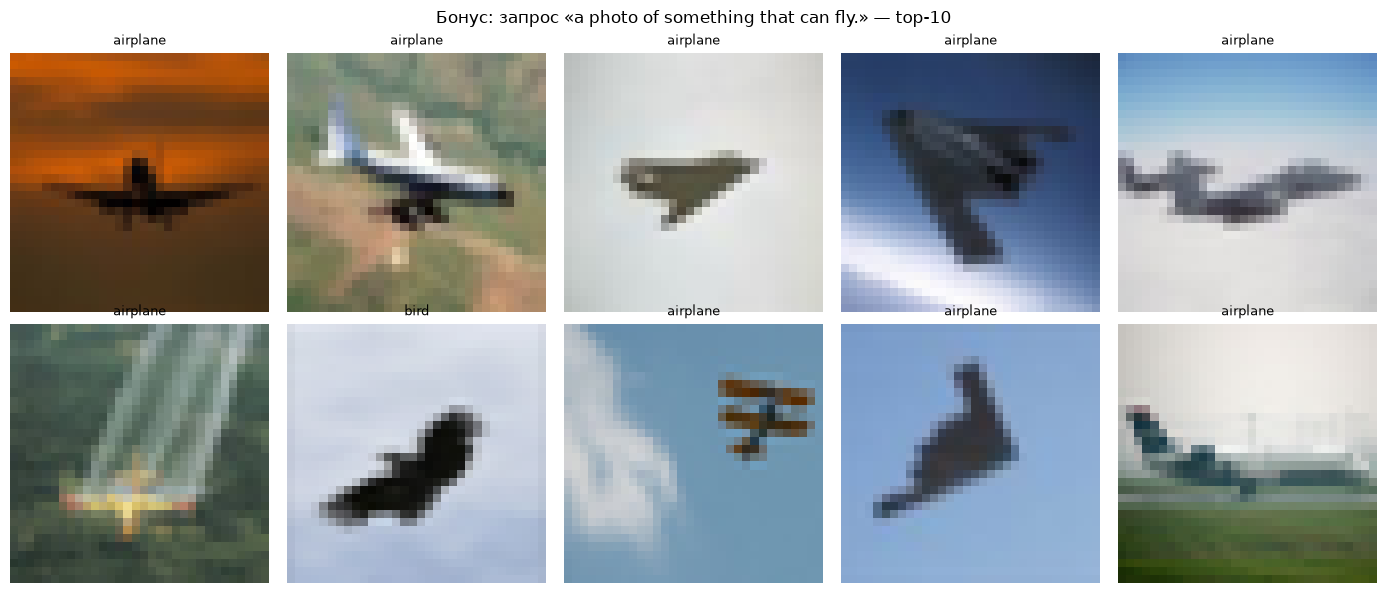

✔ Бонус: bonus_retrieval.png и bonus_query.json сохранены


In [13]:
import matplotlib.pyplot as plt

BONUS_QUERY = "a photo of something that can fly."   # не-классовый запрос
with torch.no_grad():
    q = F.normalize(model.encode_text(tokenizer([BONUS_QUERY]).to(DEVICE)).float(), dim=1)[0].cpu()
top10 = torch.topk(IMG_TEST @ q, 10).indices.numpy()

fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for k, ax in enumerate(axes.flat):
    ax.imshow(base_test.data[test_idx[top10[k]]])
    ax.set_title(classes[int(Y_TEST[top10[k]])], fontsize=9)
    ax.axis("off")
plt.suptitle(f"Бонус: запрос «{BONUS_QUERY}» — top-10")
plt.tight_layout()
plt.savefig(ARTIFACTS / "bonus_retrieval.png", dpi=150)
plt.show()

with open(ARTIFACTS / "bonus_query.json", "w") as f:
    json.dump({"query": BONUS_QUERY,
               "top10_test_idx": [int(test_idx[i]) for i in top10],
               "top10_labels": [classes[int(Y_TEST[i])] for i in top10]}, f, indent=4)
check(True, "Бонус: bonus_retrieval.png и bonus_query.json сохранены")

## Анализ результатов

Сопоставьте измеренные показатели на отложенных реальных данных. Укажите бюджет, ошибки модели и ограничения сокращённого запуска.


## Выводы

Сформулируйте предметный вывод по сохранённым артефактам.
